In [1]:
import sys
import os
import json
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'robot-2026-zimmermann'

In [4]:
file_id = 19

weights = (0.1, -0.25, 1.)

neuron_labels = [f'N{i}' for i in range(20)]
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [5]:
manual = True

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename_gcamp,
 discrete_states, eigenworms) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

In [7]:
# generate
(filename,
 modes,
 traces_reconstructed,
 traces_residual,
 traces,
 params,
 params_manifold) = generate_utils.artificialize(weights, 'hgm',
												 filename_gcamp,
												 neuron_labels,
												 eigenworms,
												 discrete_states[bhl_selection],
												 n_dimensions=len(bhl_selection))

In [8]:
neuron_labels = neuron_labels[:5]

In [9]:
_, bom_man, bom_rec, bom_res, bom_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)
_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)

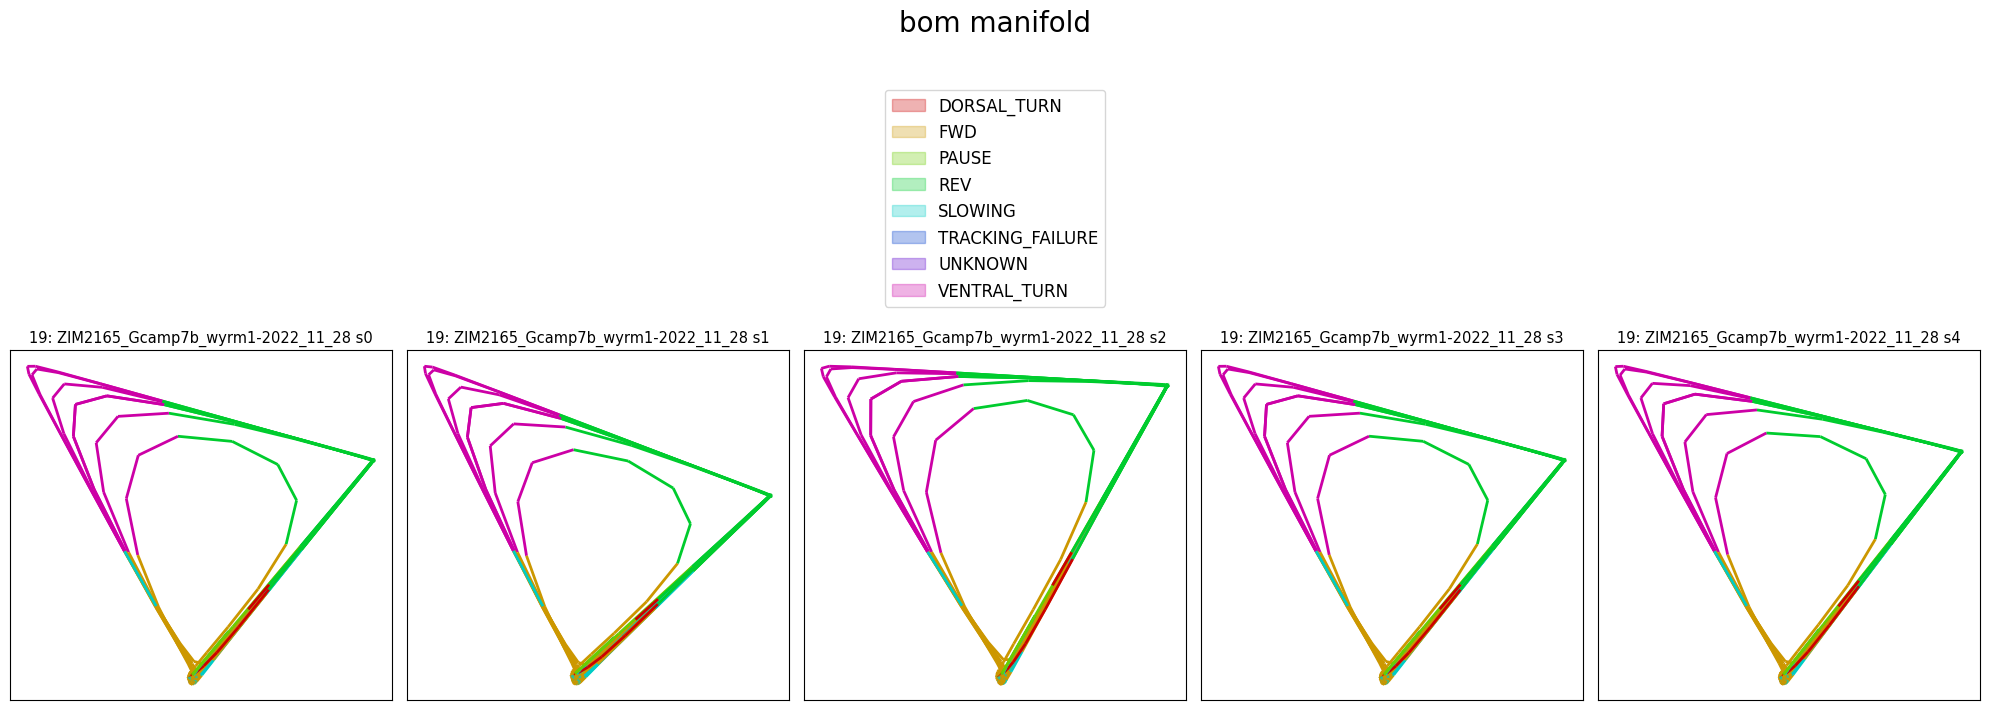

In [10]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [bom_man[s] for s in range(splits)],
						  [discrete_states for s in range(splits)],
						  None, None,
						  title='bom manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

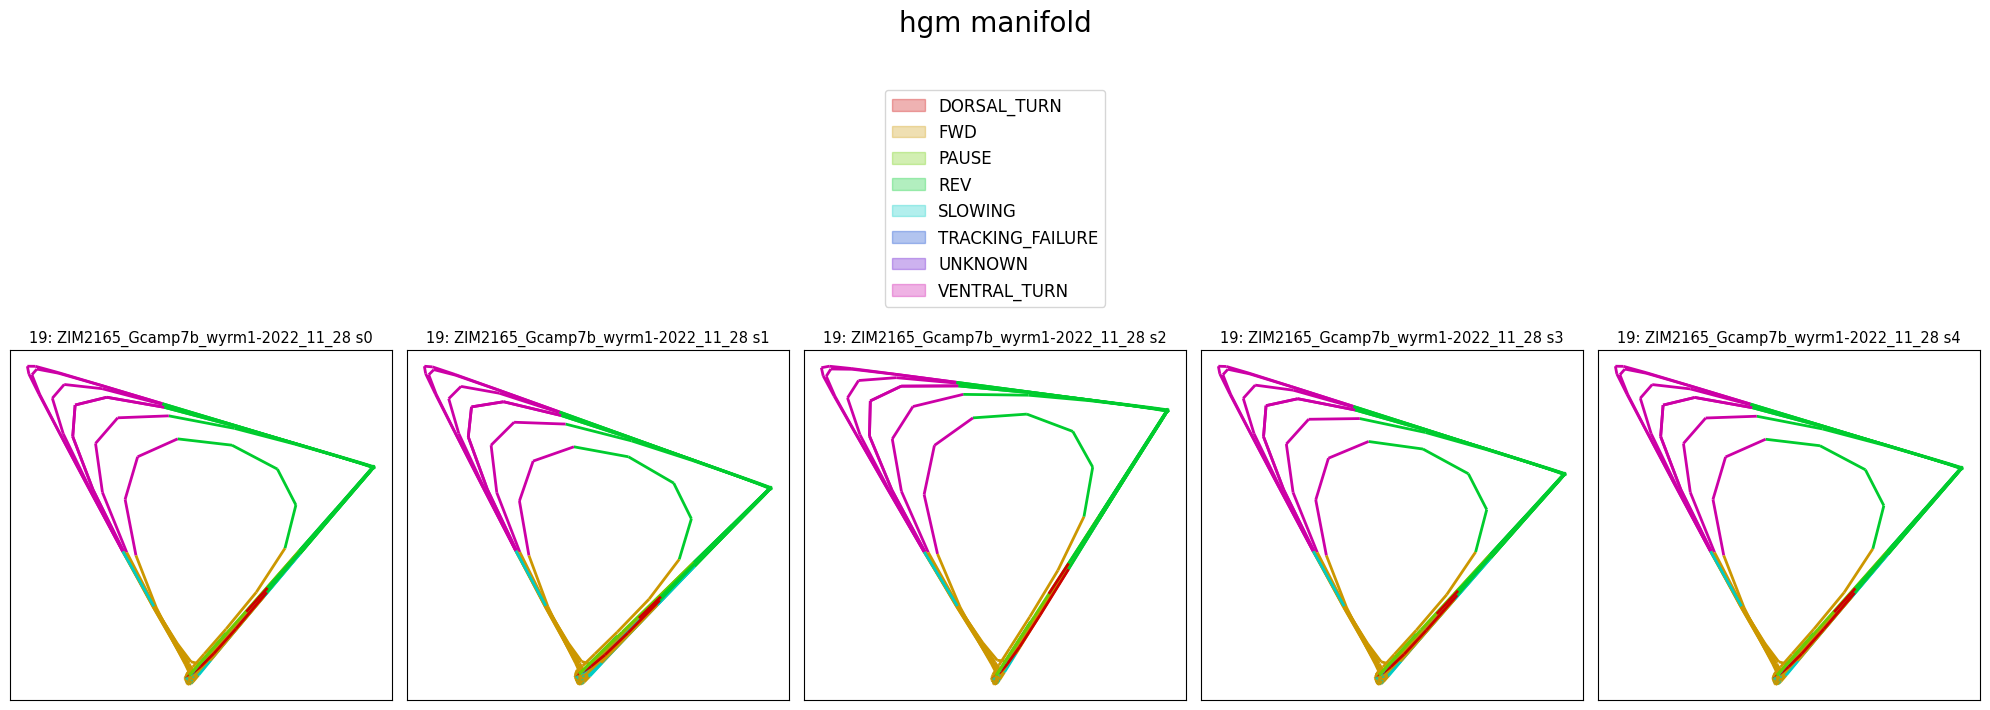

In [11]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [discrete_states for s in range(splits)],
						  None, None,
						  title='hgm manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

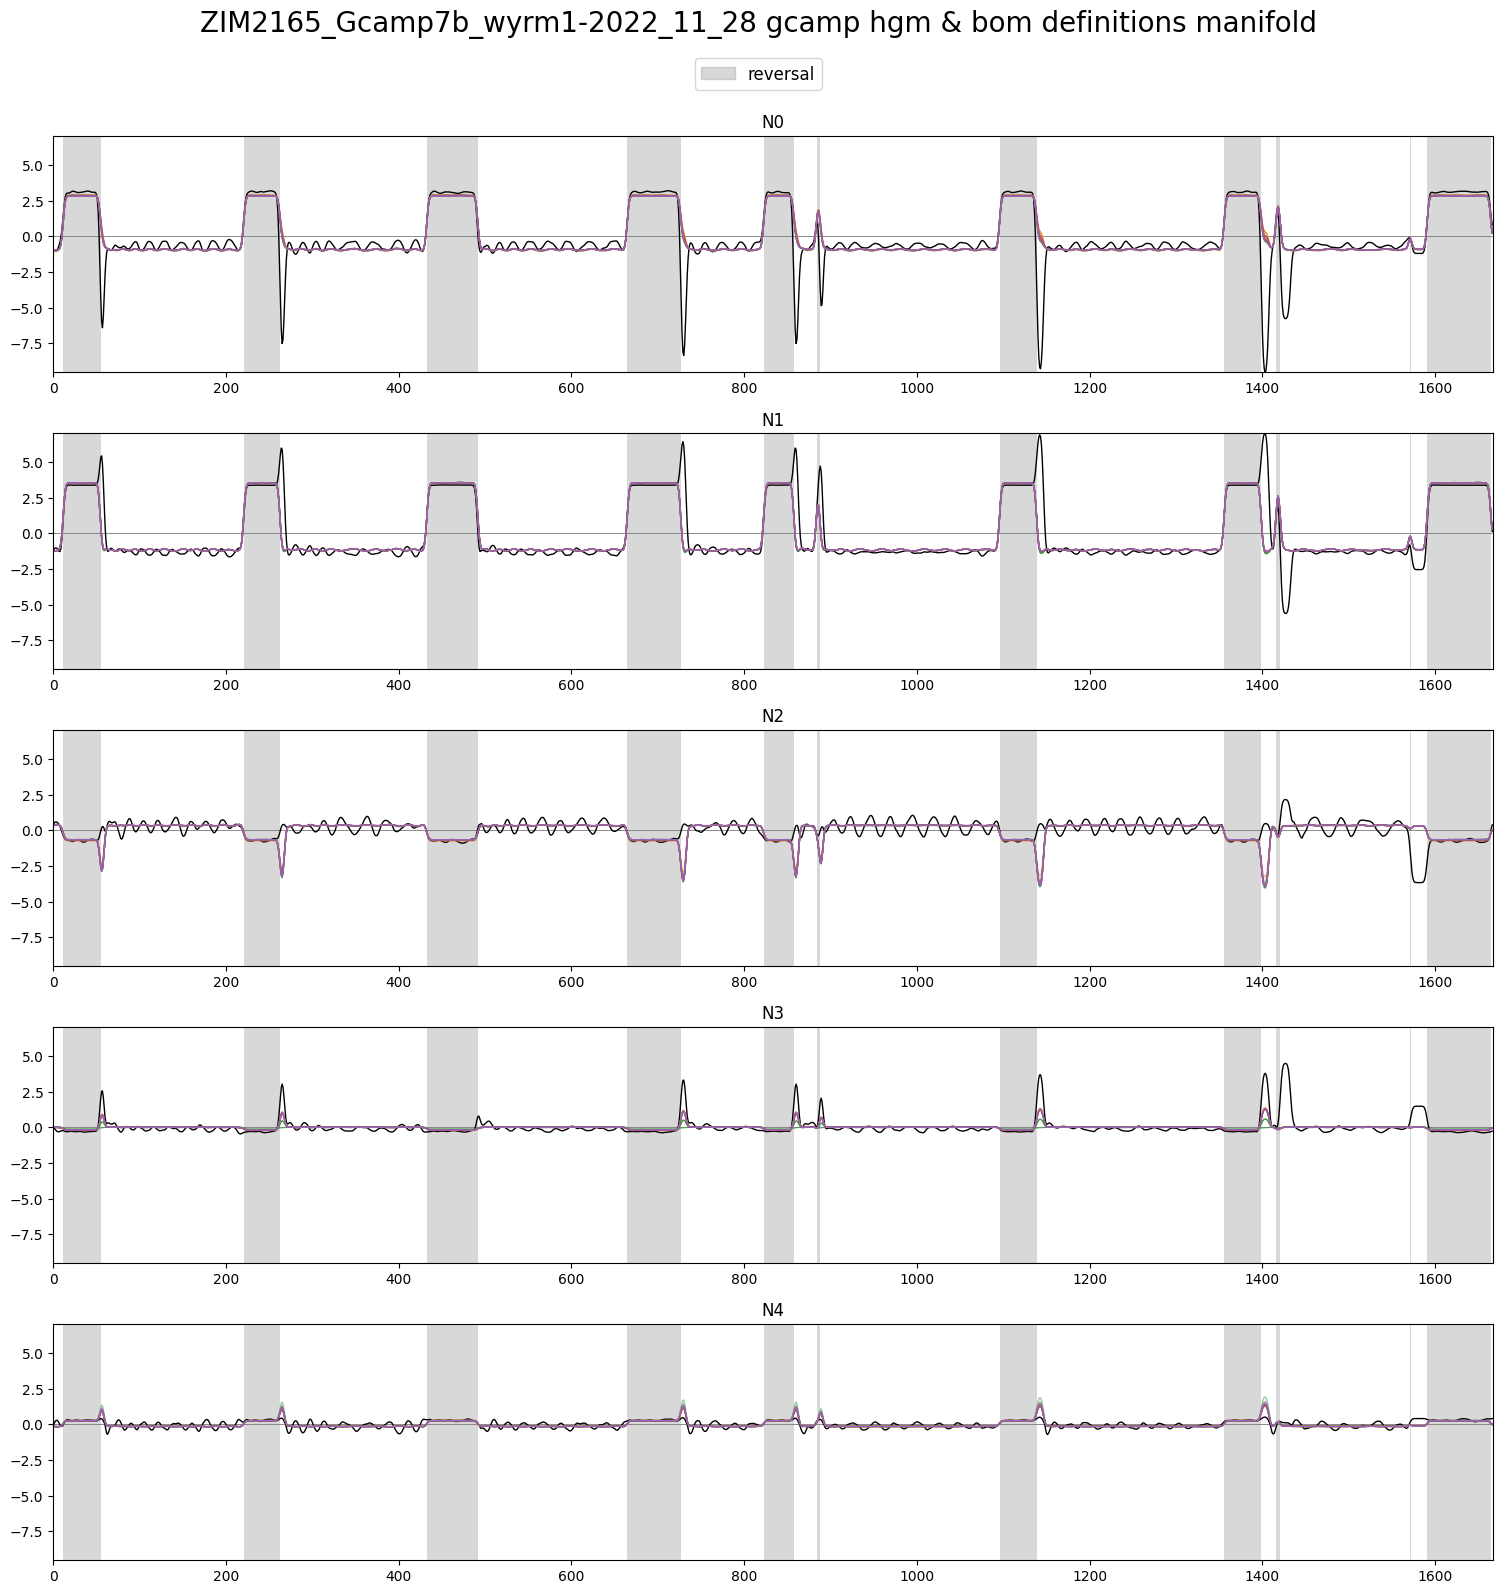

In [12]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neuron_labels] for i in range(splits)],
	[bom_rec[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

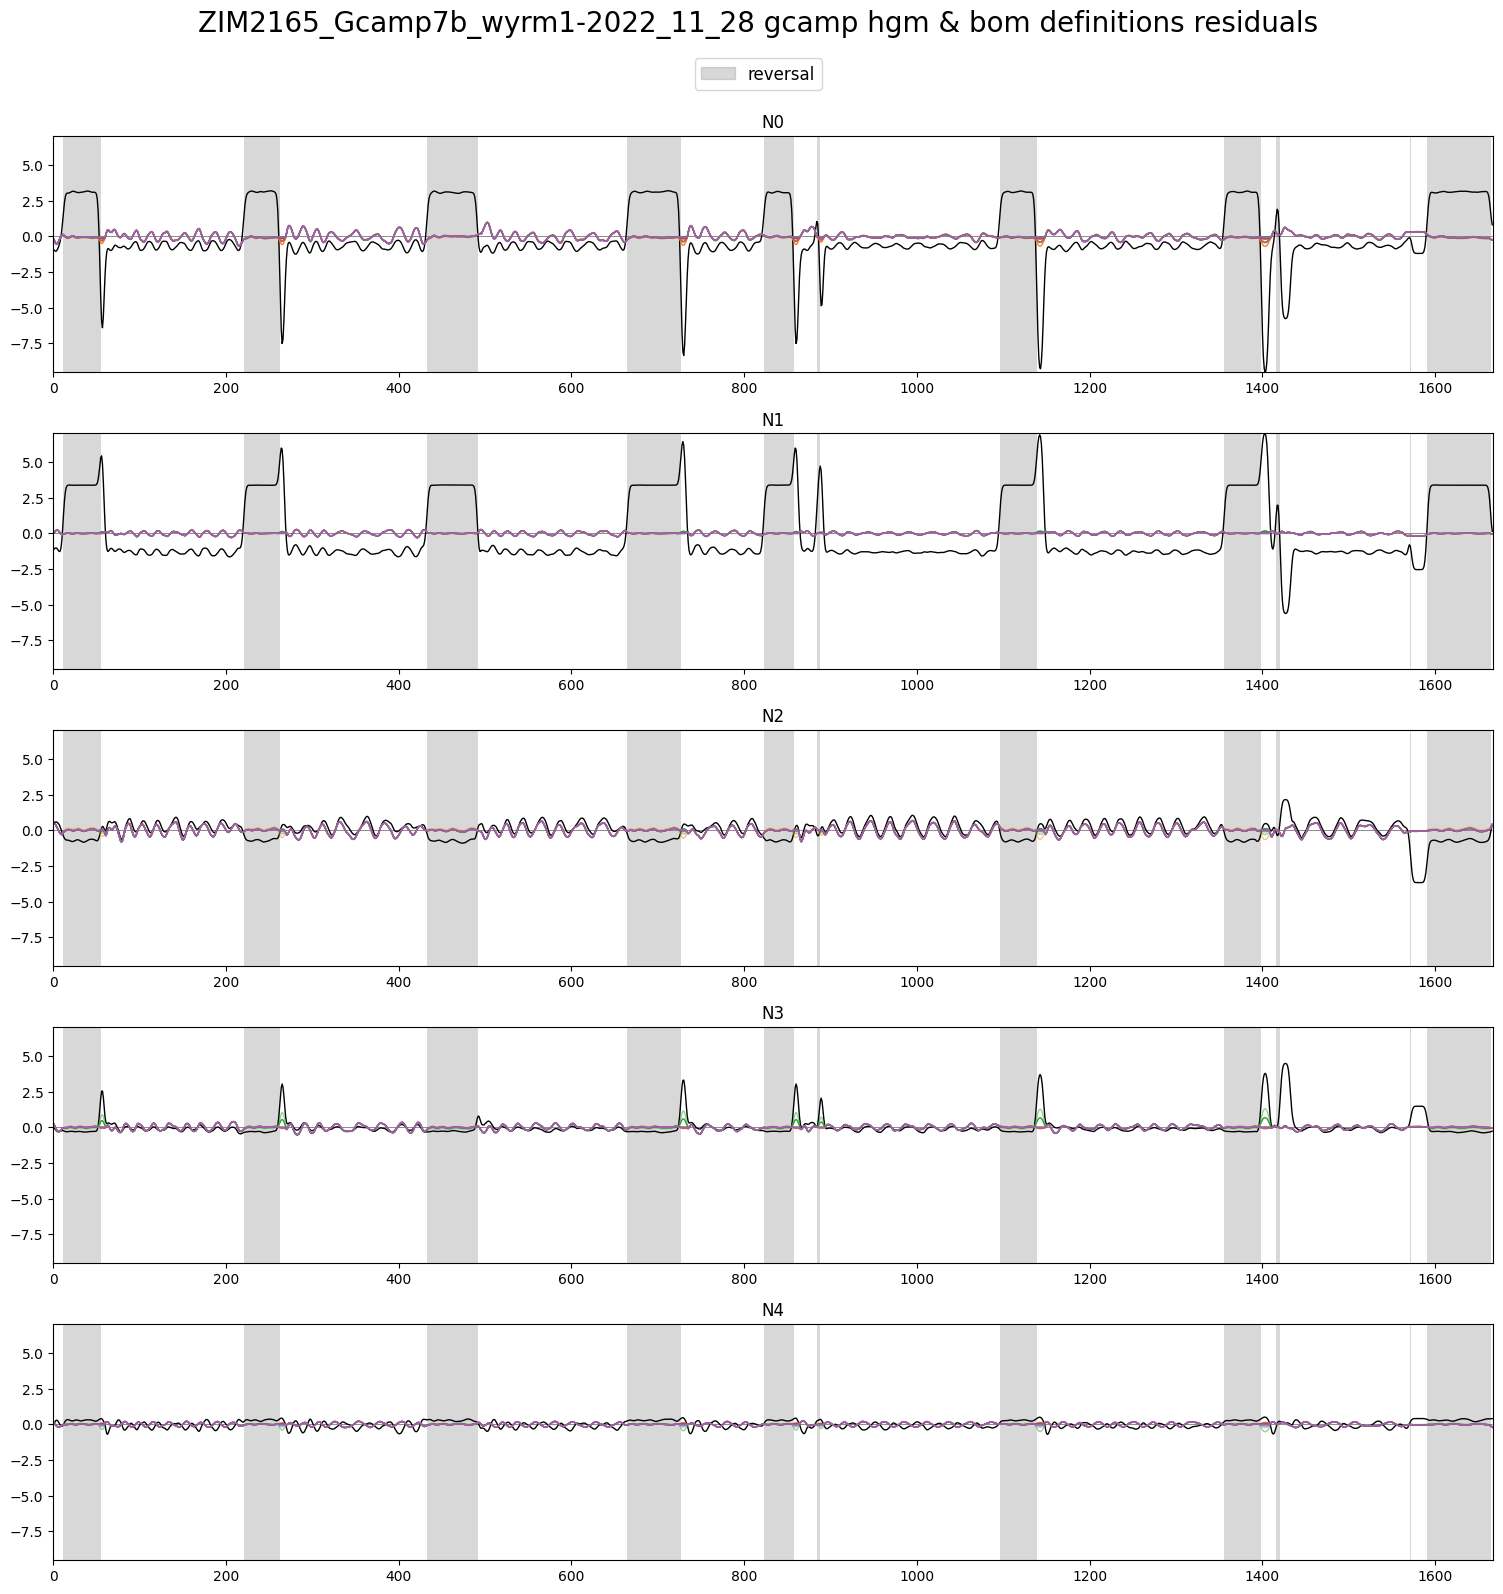

In [13]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neuron_labels] for i in range(splits)],
	[bom_res[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

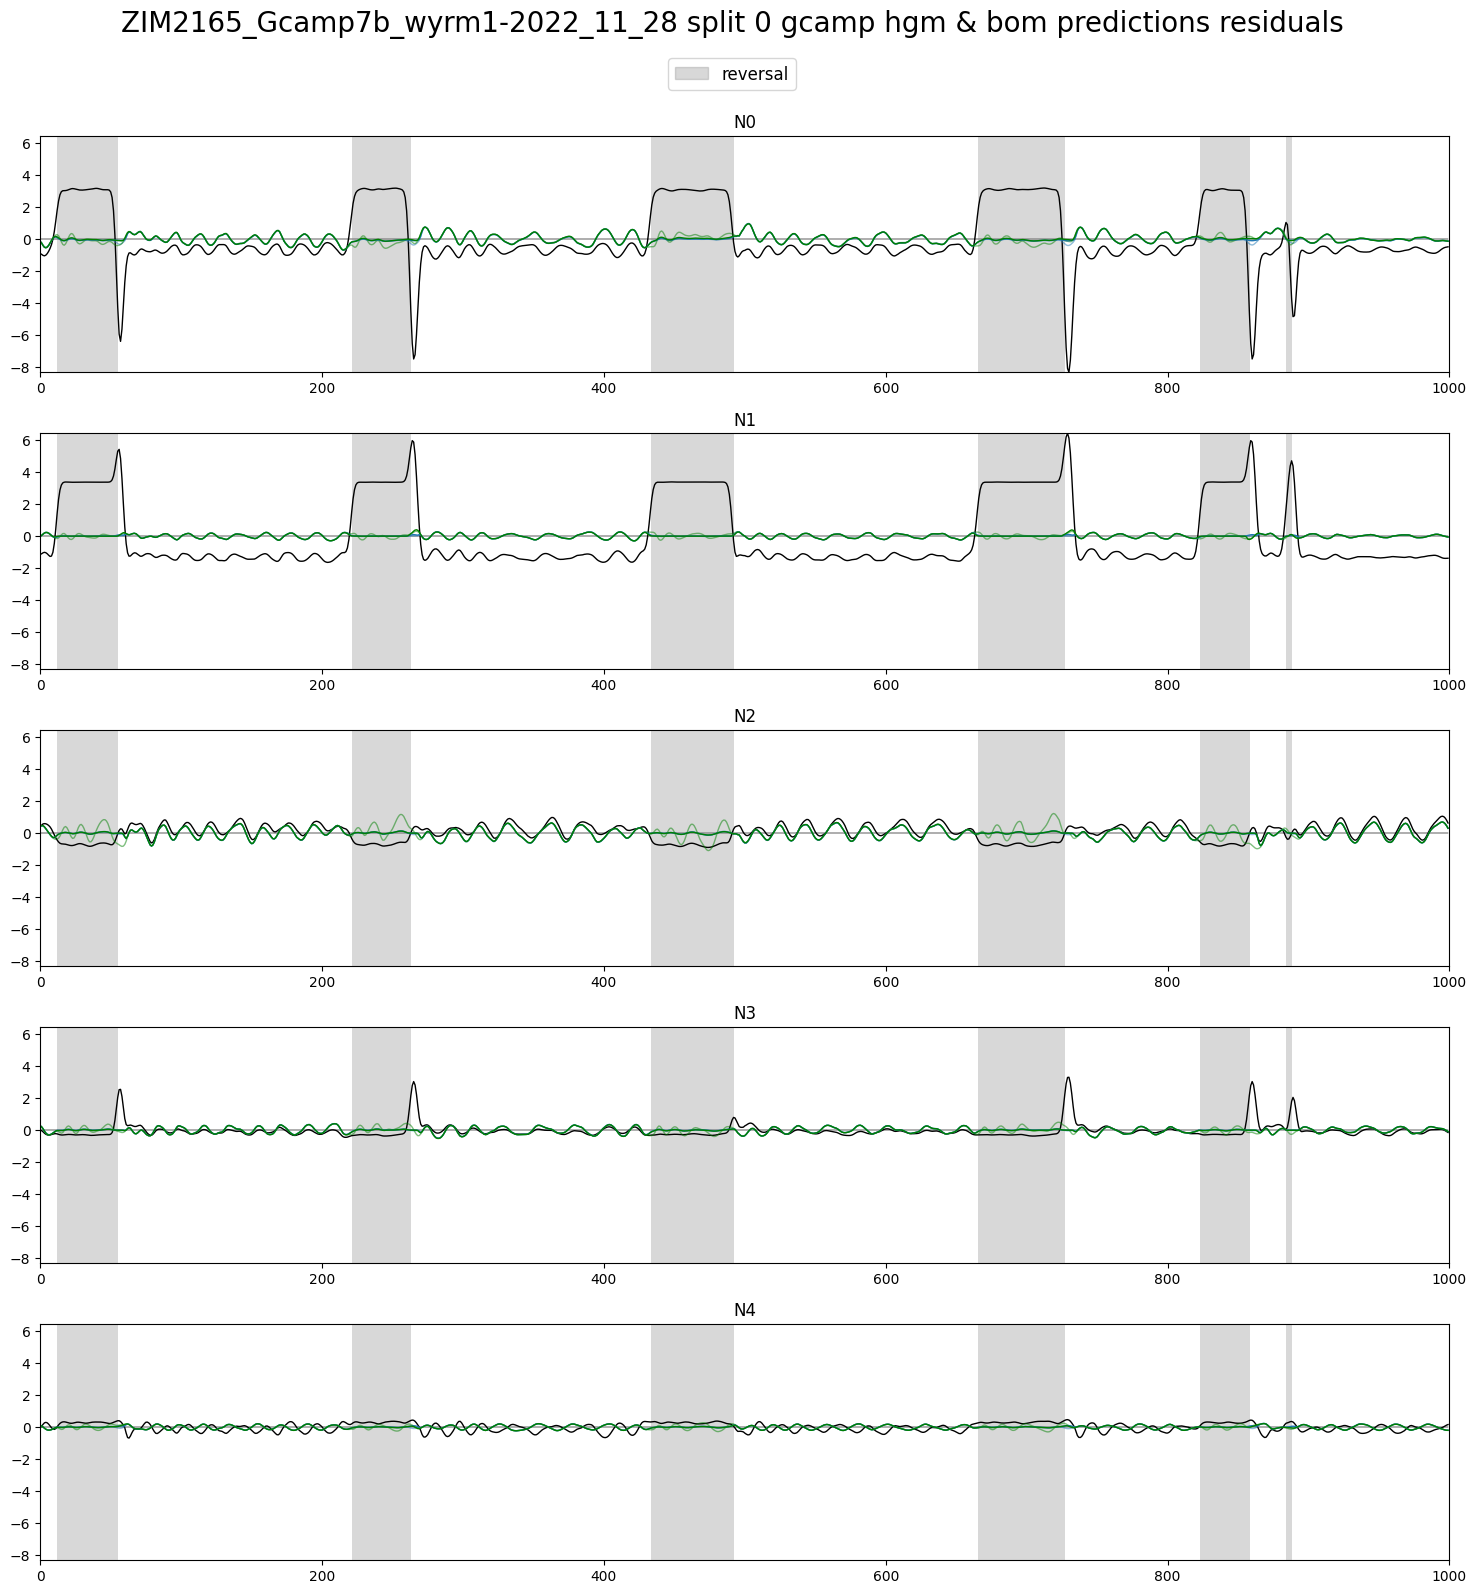

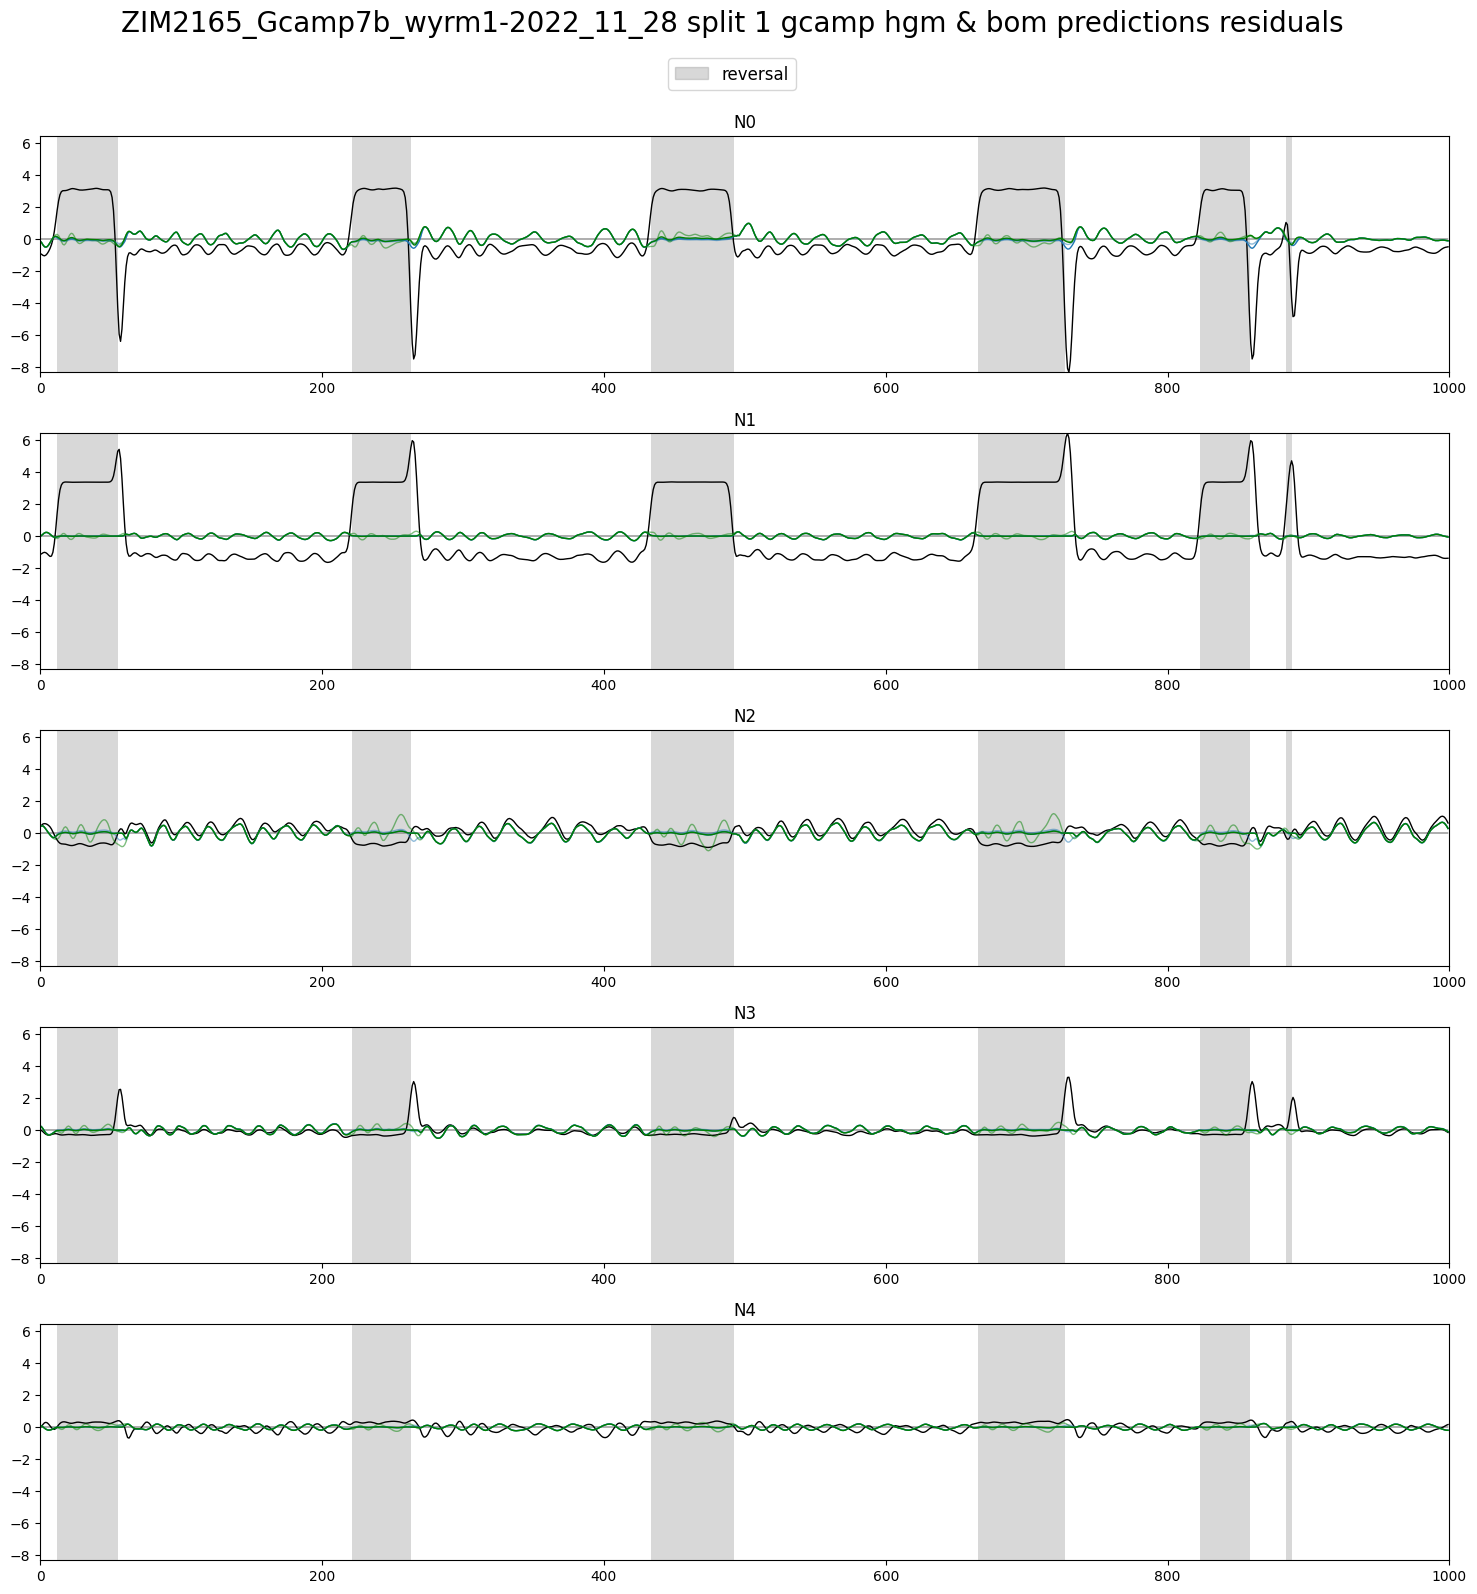

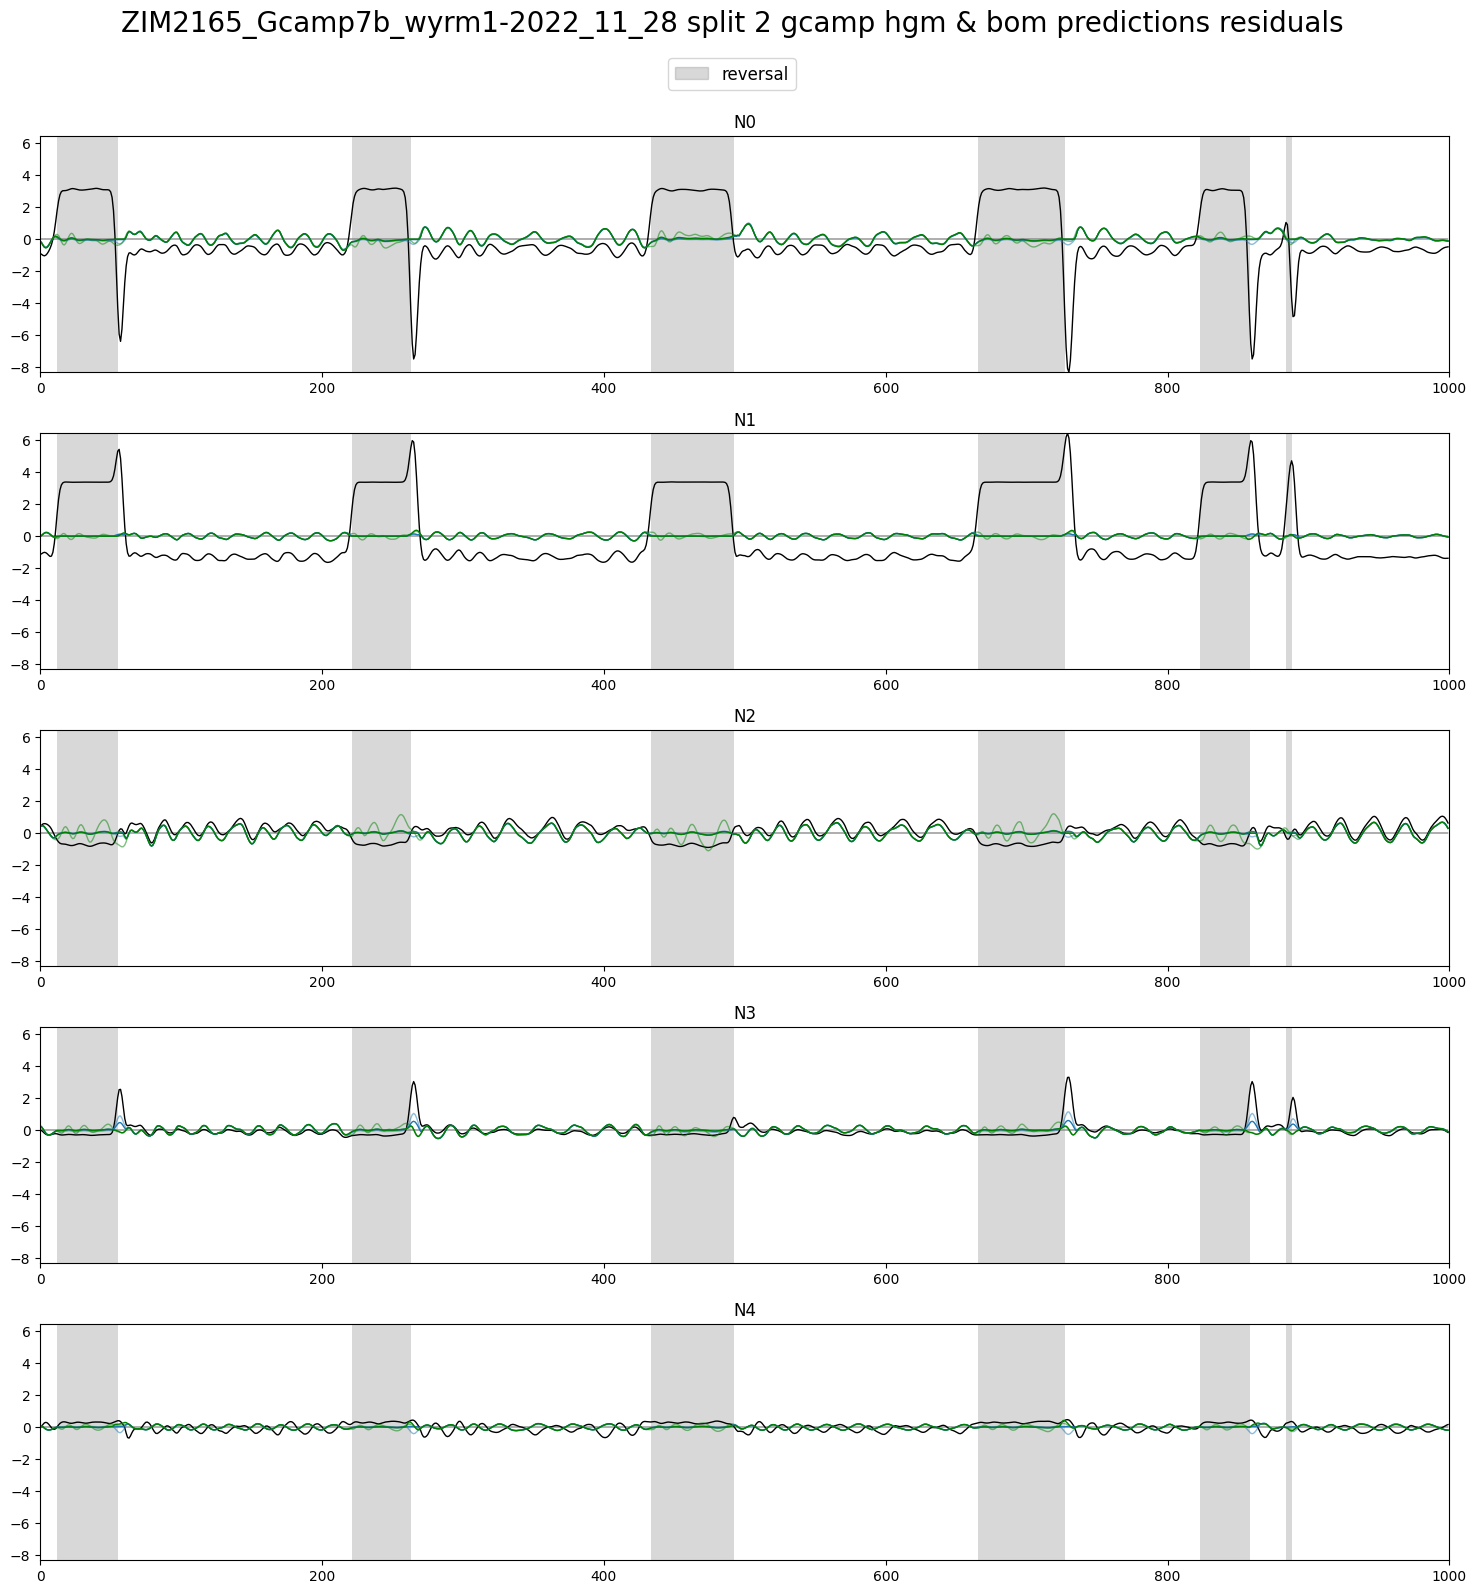

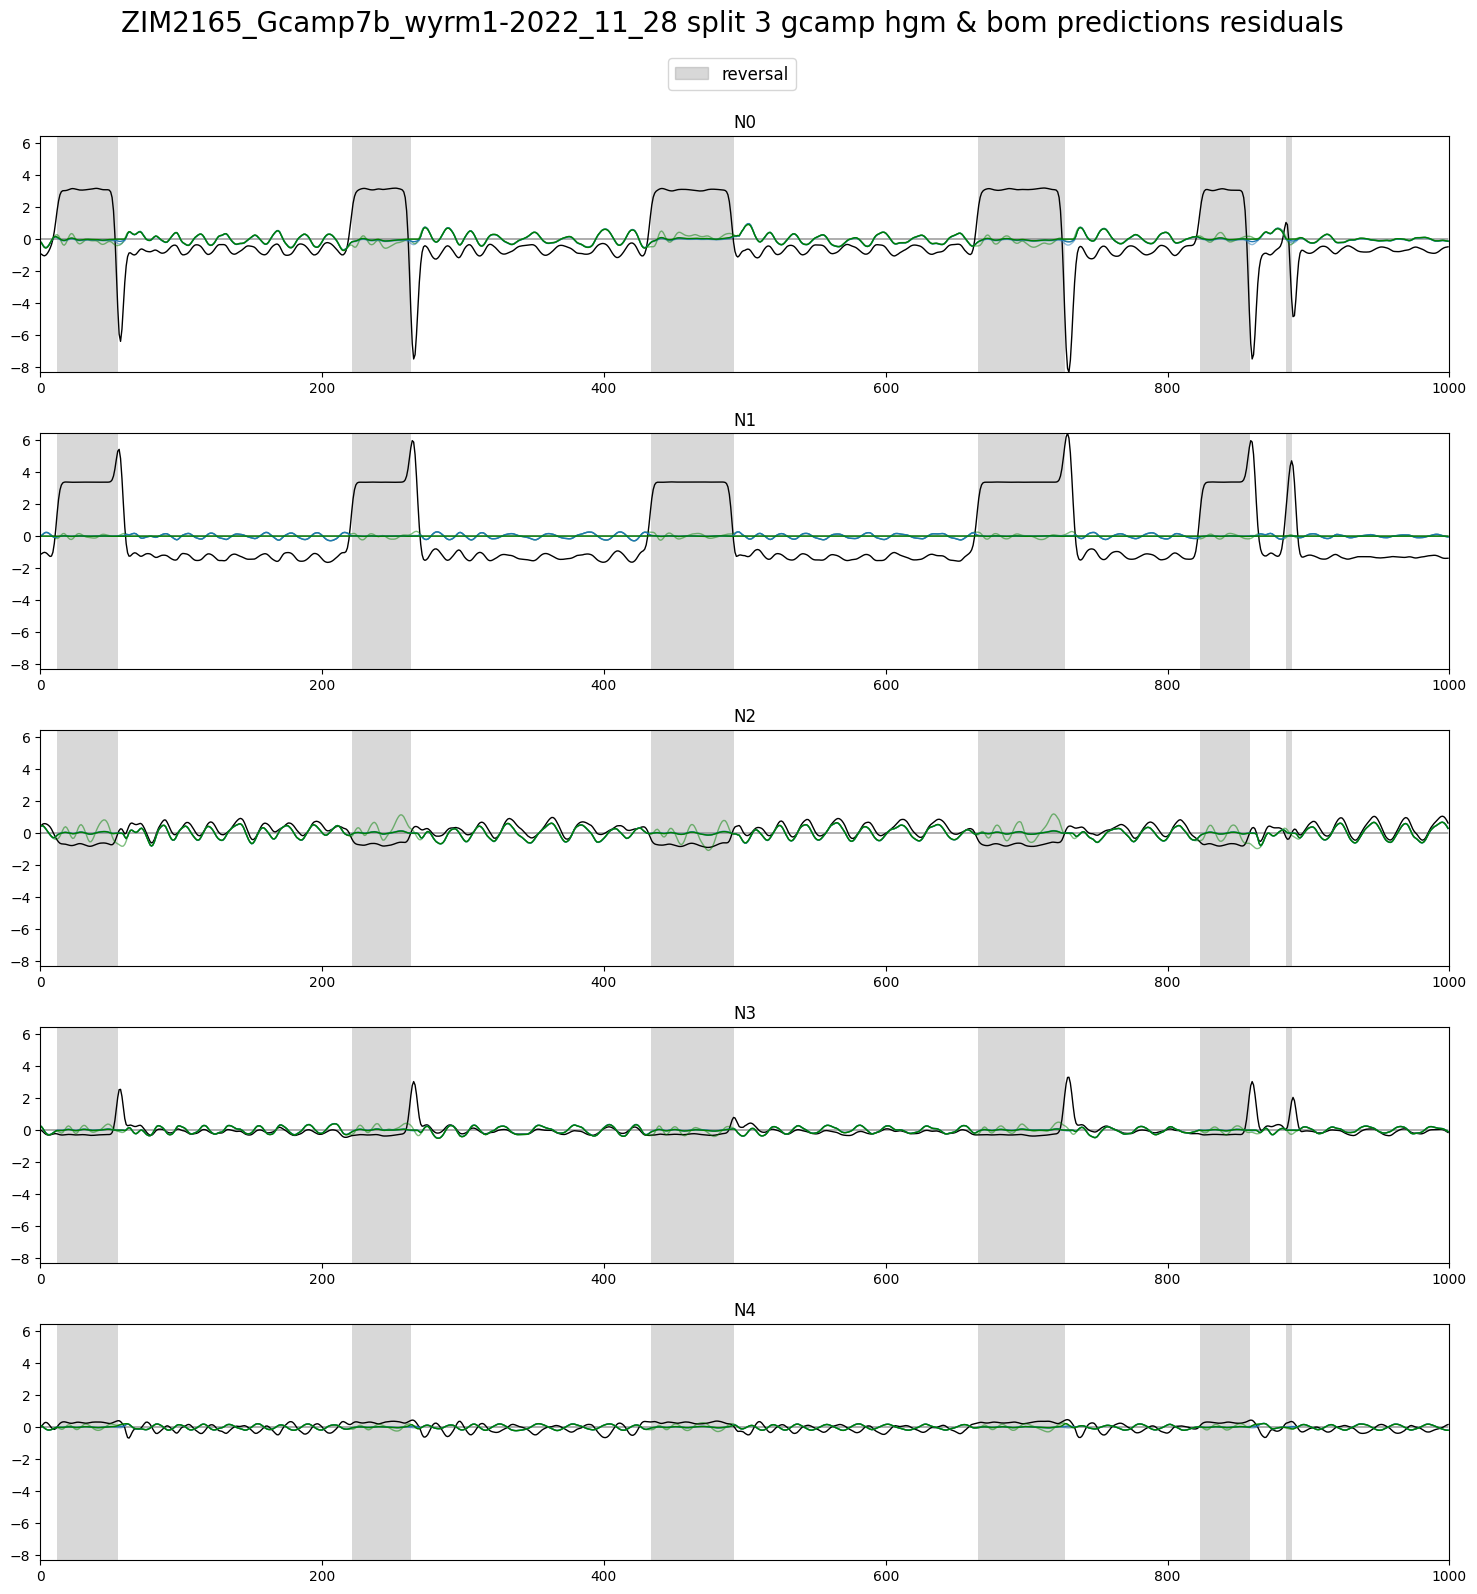

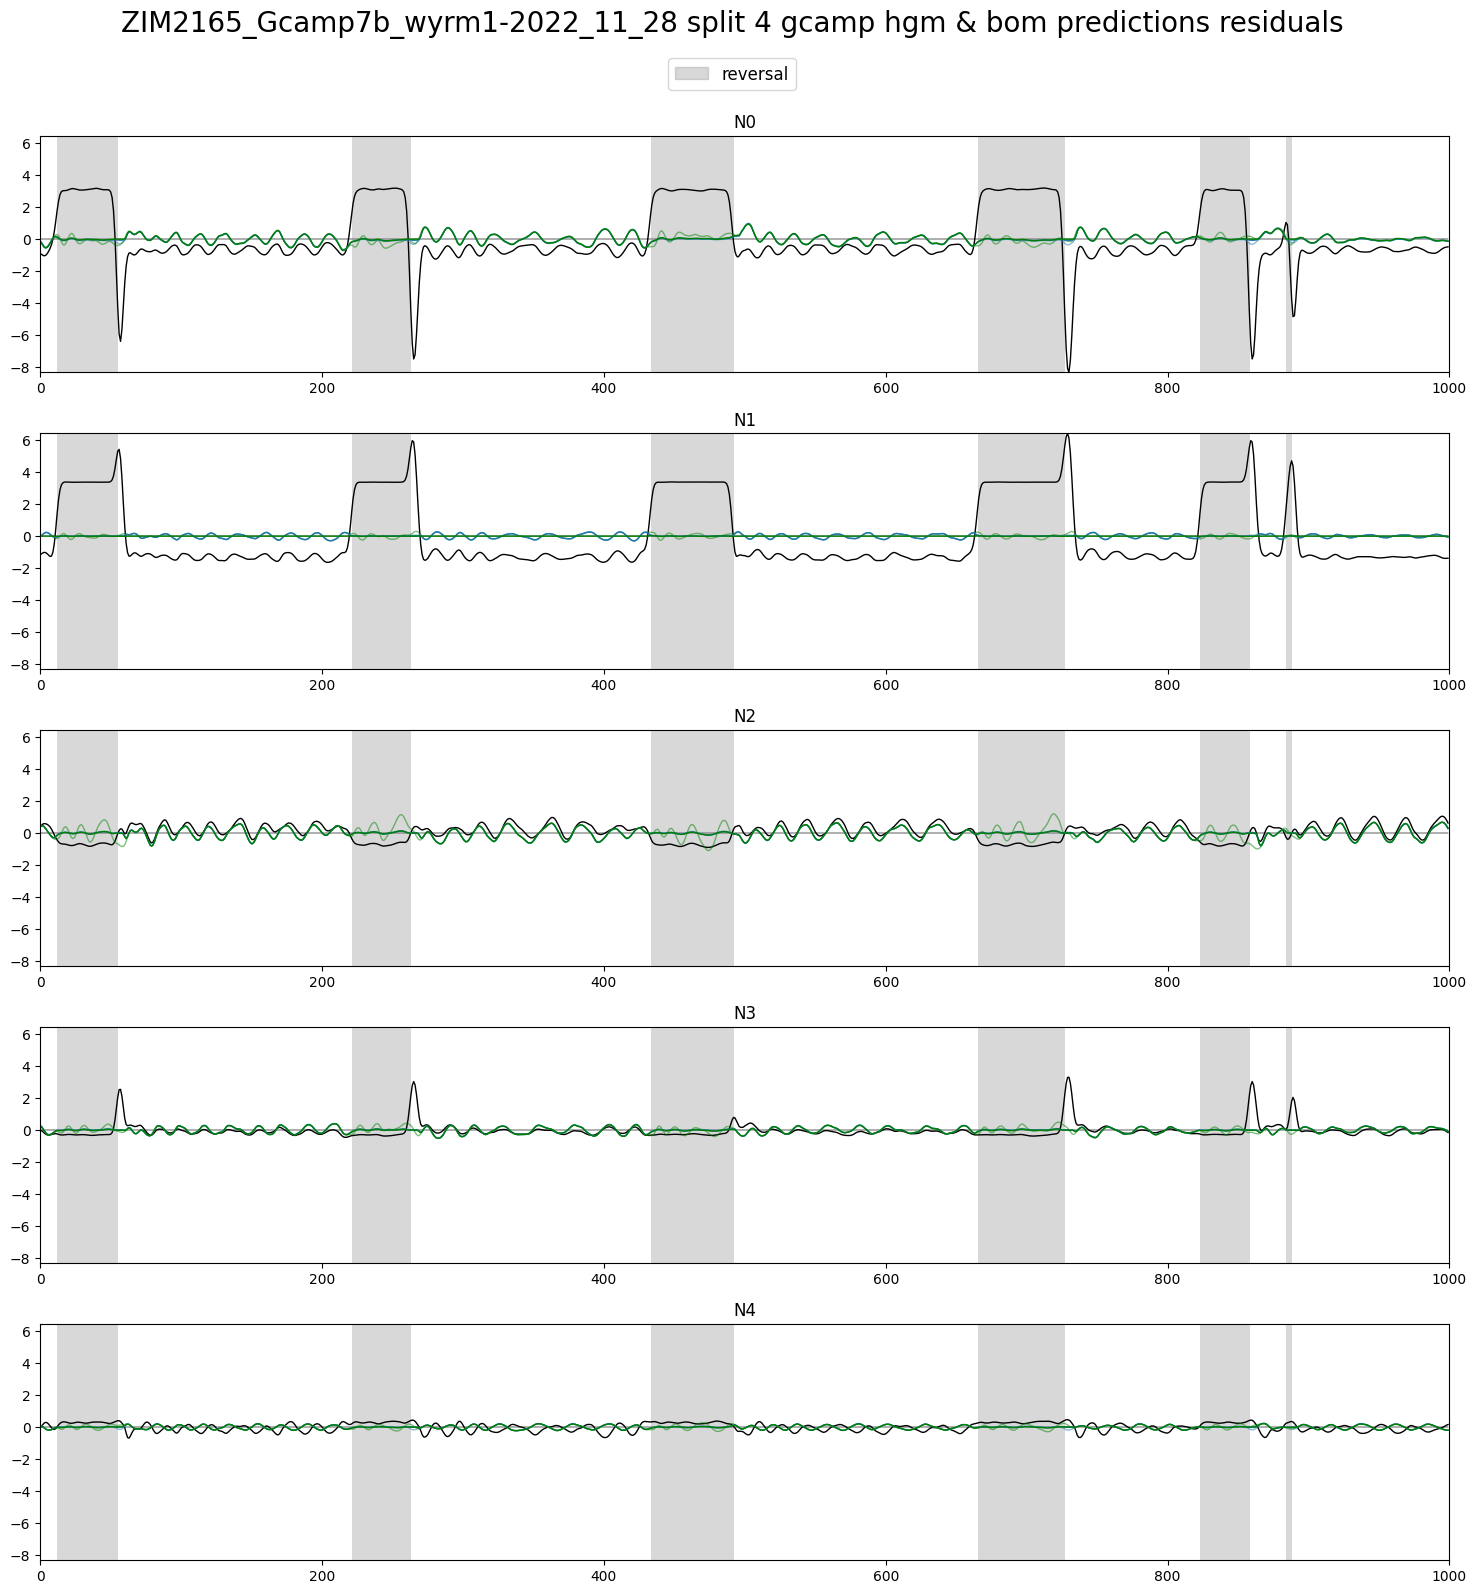

In [14]:
# max_x = traces.values.shape[0]
max_x = 1000

splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neuron_labels].iloc[:max_x, :],
		 hgm_pres[i][neuron_labels].iloc[:max_x, :]],
		[bom_res[i][neuron_labels].iloc[:max_x, :],
		 bom_pres[i][neuron_labels].iloc[:max_x, :]],
		traces[neuron_labels].iloc[:max_x, :],
		discrete_states[['REV']].iloc[:max_x, :], label='reversal',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

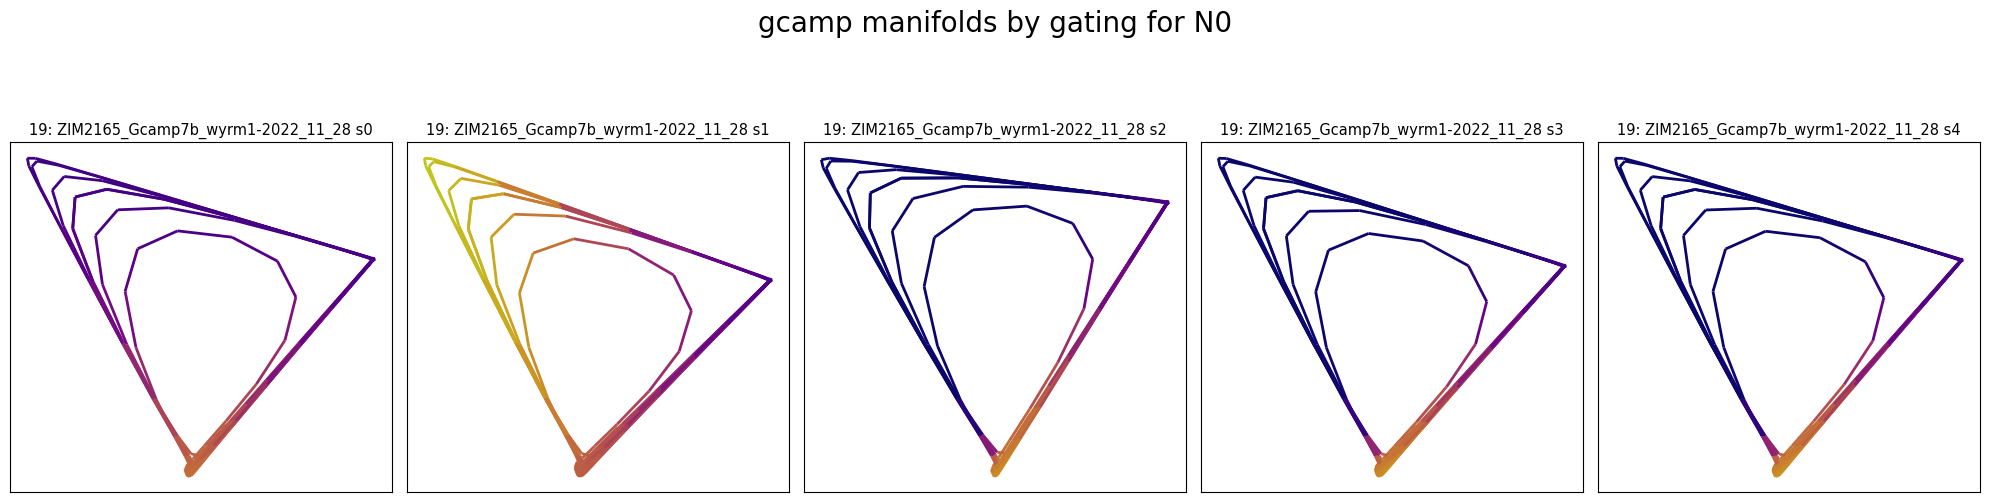

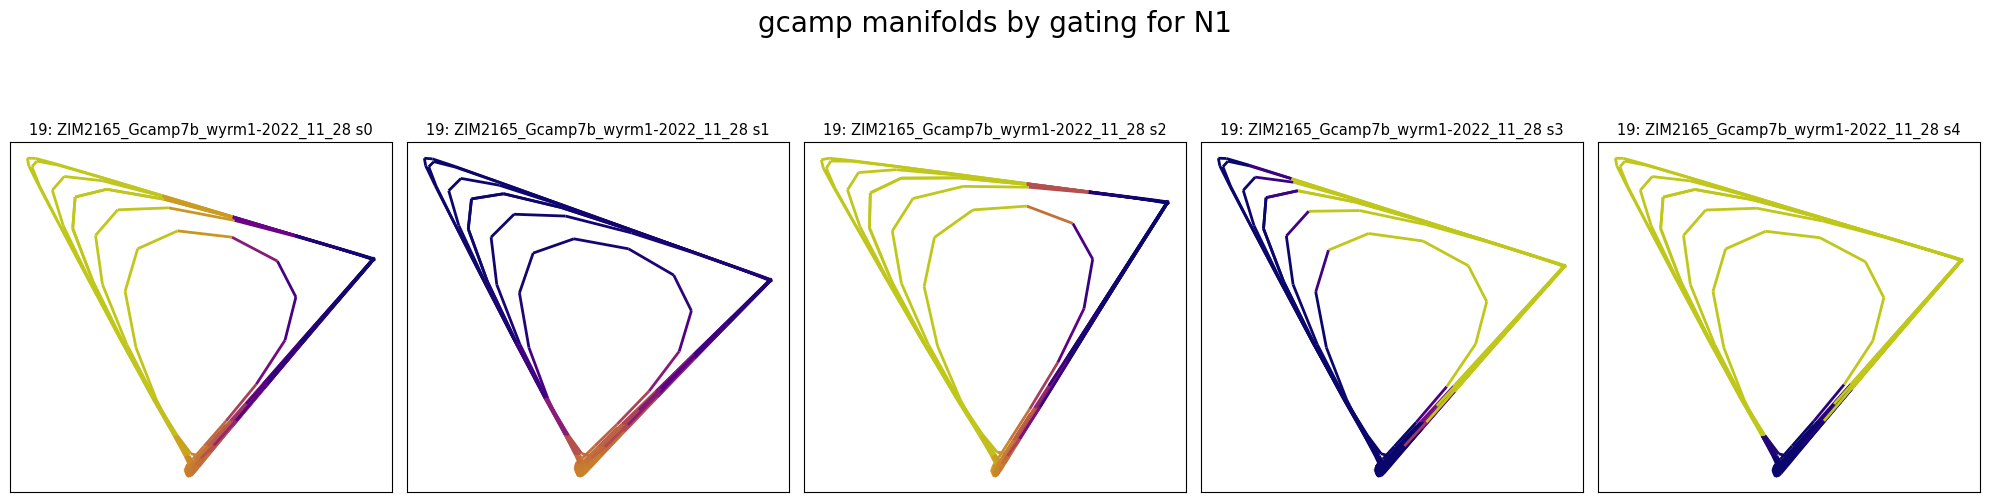

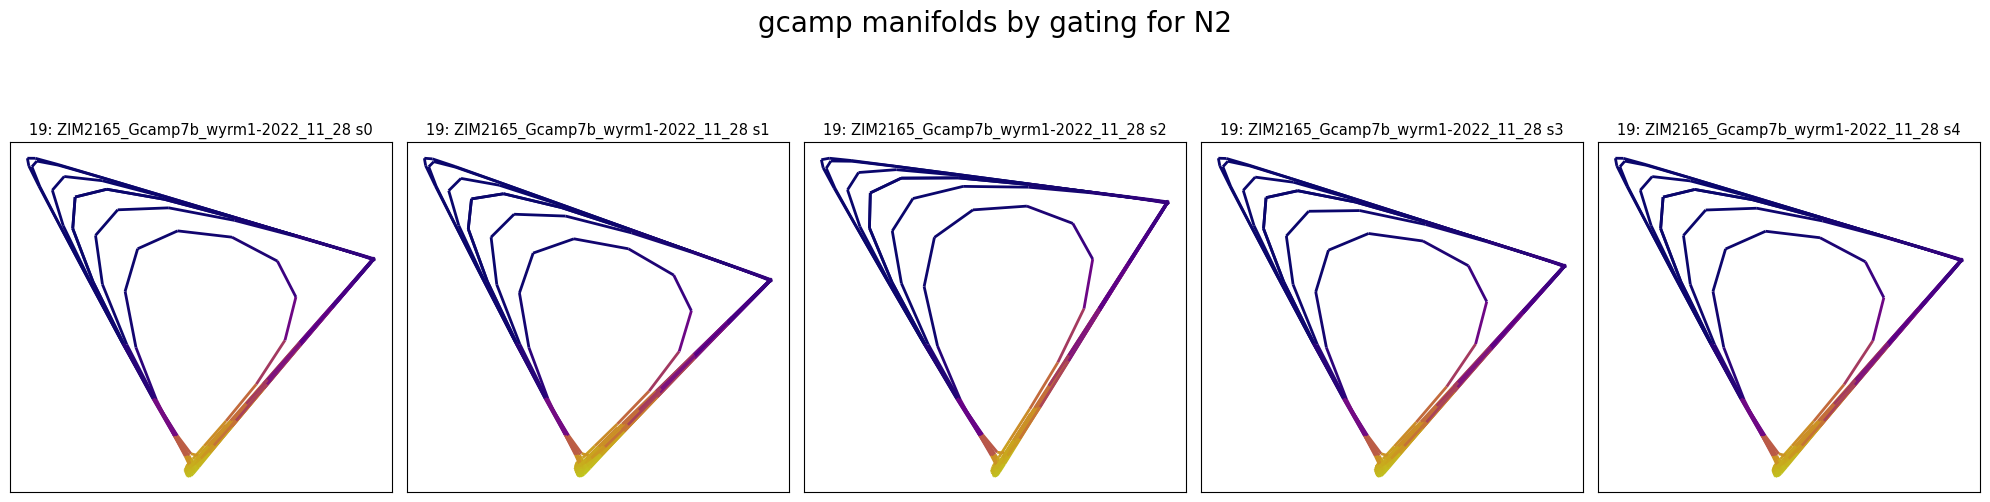

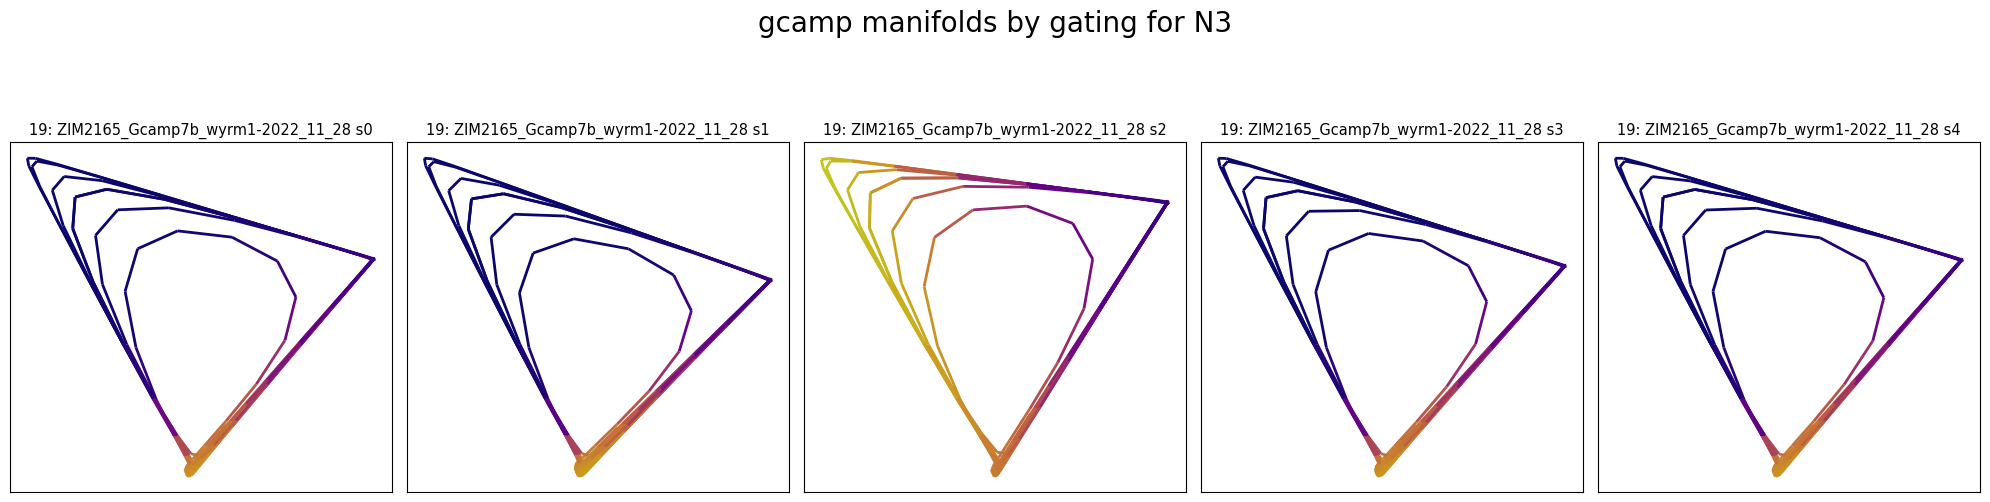

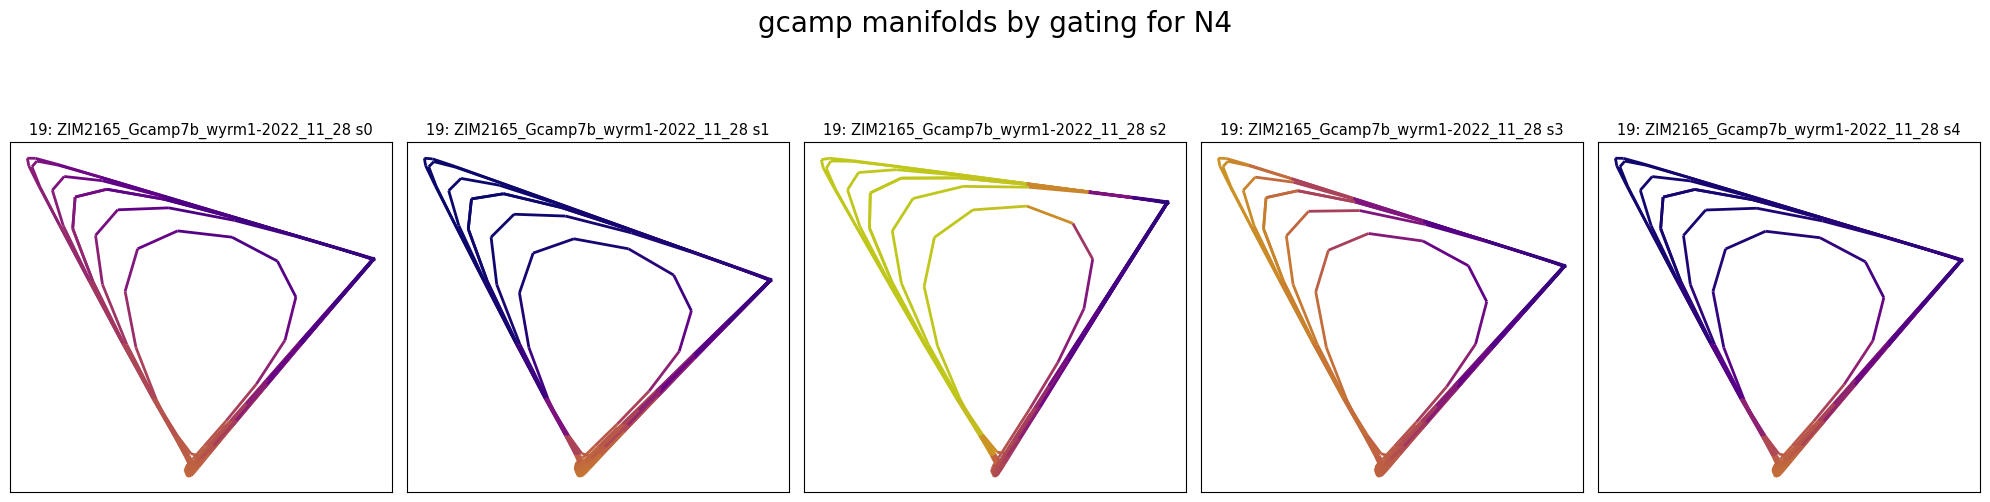

In [15]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

hgm_folder = f'{data_variant}_hgm_{model_variant}_' + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()])
hgm_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', hgm_folder), filename)

neurons = neuron_labels
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neurons]

splits = 5

for neuron_id in neuron_ids:
	sigmoid_terms = list()
	for split in range(splits):
		manifold_term = hgm_man[split].values
		manifold_term_zs = (manifold_term - manifold_term.mean(axis=0)) / np.where((N_std := manifold_term.std(axis=0)) == 0.0, 1.0, N_std)

		WM = hgm_params[split]['model']['WM'][:, neuron_id]

		sigmoid_term = sigmoid(manifold_term_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
							  [hgm_man[s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  None, None,
							  title=f'gcamp manifolds by gating for {traces.columns[neuron_id]}', plots_per_row=splits, top_space=1,
							  save_path=None)